# Perceived Educational Returns & Career Satisfaction in Malaysia
### Data Analysis Notebook

This notebook analyses the relationship between **perceived educational returns** (employability confidence, skill relevance, income expectations) and **career satisfaction** among Malaysian respondents. The analysis mirrors the SEM-based study described in the abstract, covering:

1. Data loading & inspection
2. Descriptive statistics & demographics
3. Missing data & data quality checks
4. Reliability analysis (Cronbach's α)
5. Construct validity (EFA / CFA via factor analysis)
6. Correlation analysis
7. Regression analysis (predictor importance)
8. Structural Equation Modelling (SEM)
9. Subgroup comparisons (education level)
10. Expectation–Reality Gap analysis
11. Robustness checks
12. Visualisations

---
## 0. Install & Import Libraries

In [1]:
# Install any missing libraries (skips packages that are already installed)
import importlib.util, subprocess, sys
REQUIRED = {'semopy': 'semopy', 'pingouin': 'pingouin', 'factor_analyzer': 'factor_analyzer',
            'openpyxl': 'openpyxl', 'missingno': 'missingno'}
missing = [pip for mod, pip in REQUIRED.items() if importlib.util.find_spec(mod) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('Missing packages installed:', missing or 'none')


Missing packages installed: none


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from scipy import stats
from scipy.stats import pearsonr, spearmanr
import pingouin as pg
from factor_analyzer import FactorAnalyzer
from sklearn.preprocessing import StandardScaler
import semopy
import missingno as msno

# Compatibility: newer scikit-learn renamed check_array's `force_all_finite` to `ensure_all_finite`,
# which makes FactorAnalyzer.fit() raise a TypeError. Translate the keyword; results are unchanged.
import inspect
import factor_analyzer.factor_analyzer as _fa_mod
from sklearn.utils.validation import check_array as _check_array
if 'force_all_finite' not in inspect.signature(_check_array).parameters:
    def _compat_check_array(*args, **kwargs):
        if 'force_all_finite' in kwargs:
            kwargs['ensure_all_finite'] = kwargs.pop('force_all_finite')
        return _check_array(*args, **kwargs)
    _fa_mod.check_array = _compat_check_array

# Plot style
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)
plt.rcParams['figure.dpi'] = 120
plt.rcParams['figure.figsize'] = (10, 5)

print('All libraries loaded successfully.')

All libraries loaded successfully.


---
## 1. Load Data

In [3]:
FILE_PATH = 'edu_return_data.xlsx'   # not public: available from the corresponding author on request

df = pd.read_excel(FILE_PATH, sheet_name=0)

# Exclude respondents aged below 18 before anything is printed or analysed
df = df[df['AgeGroup'] != 'Below 18'].reset_index(drop=True)
print(f'Analysed sample: {df.shape[0]} respondents, {df.shape[1]} columns (respondents aged below 18 excluded)')


Analysed sample: 380 respondents, 29 columns (respondents aged below 18 excluded)


In [4]:
# Column overview
print(df.dtypes)
print('\nColumn names:')
for c in df.columns:
    print(' ', c)

Gender             object
AgeGroup           object
YearStudy          object
FieldStudy         object
EducationLevel     object
EMP1                int64
EMP2                int64
EMP3                int64
EMP4                int64
EMP5                int64
SR1                 int64
SR2                 int64
SR3                 int64
SR4                 int64
SR5                 int64
IE1                 int64
IE2                 int64
IE3                 int64
IE4                 int64
IE5                 int64
CS1                 int64
CS2                 int64
CS3                 int64
CS4                 int64
CS5                 int64
EMP_Mean          float64
SR_Mean           float64
IE_Mean           float64
CS_Mean           float64
dtype: object

Column names:
  Gender
  AgeGroup
  YearStudy
  FieldStudy
  EducationLevel
  EMP1
  EMP2
  EMP3
  EMP4
  EMP5
  SR1
  SR2
  SR3
  SR4
  SR5
  IE1
  IE2
  IE3
  IE4
  IE5
  CS1
  CS2
  CS3
  CS4
  CS5
  EMP_Mean
  SR_Mean
  IE_Mean

---
## 2. Data Preparation

> **Action required:** Map your actual column names to the construct groups below.

In [5]:
CONSTRUCT_MAP = {
    # Perceived Educational Returns (IV)
    'employability':    ['EMP1', 'EMP2', 'EMP3', 'EMP4', 'EMP5'],   # Employability confidence items (all 5 retained)
    'skill_relevance':  ['SR1', 'SR2', 'SR3', 'SR4', 'SR5'],   # Skill relevance items (all 5 retained)
    'income_expect':    ['IE1', 'IE2', 'IE3', 'IE4', 'IE5'],   # Income expectations items (all 5 retained)

    # Outcome (DV)
    'career_sat':       ['CS1', 'CS2', 'CS3', 'CS4', 'CS5'], # Career satisfaction items
}
# NOTE: previously this map dropped EMP5, SR5, IE4, and IE5 with no documented reason,
# so every downstream statistic (reliability, correlation, regression, SEM) was computed
# on only 16 of the 20 collected items. All 20 are now used.

DEMOGRAPHIC_COLS = {
    'age_group':       'AgeGroup',
    'gender':          'Gender',
    'year_study':      'YearStudy',
    'field_study':     'FieldStudy',
    'edu_level':       'EducationLevel',   # Bachelor's / Master's / Doctorate
}
# NOTE: 'employment_type', 'industry', and 'years_exp' were removed from this map because
# EmploymentType, Industry, and YearsExperience are not columns in Raw_Data; referencing
# them silently no-opped the employment-type subgroup analysis below.

# Flatten all construct items
all_items = [item for items in CONSTRUCT_MAP.values() for item in items]
print('Total construct items configured:', len(all_items))

Total construct items configured: 20


In [6]:
# Compute composite scores (mean of items per construct)
for construct, items in CONSTRUCT_MAP.items():
    # Only use items that exist in the dataframe
    valid_items = [i for i in items if i in df.columns]
    if valid_items:
        df[construct] = df[valid_items].mean(axis=1)
    else:
        print(f'WARNING: No valid columns found for construct "{construct}". Check CONSTRUCT_MAP.')

CONSTRUCTS = list(CONSTRUCT_MAP.keys())
IVs = [c for c in CONSTRUCTS if c != 'career_sat']
DV  = 'career_sat'

df[CONSTRUCTS].describe().round(3)

,employability,skill_relevance,income_expect,career_sat
count,380.000,380.000,380.000,380.000
mean,3.972,3.967,4.276,4.484
std,0.483,0.385,0.451,0.469
min,3.000,3.000,3.000,3.000
25%,3.800,4.000,4.000,4.000
50%,4.000,4.000,4.200,4.600
75%,4.000,4.000,4.600,5.000
max,5.000,5.000,5.000,5.000


---
## 3. Data Quality & Missing Values

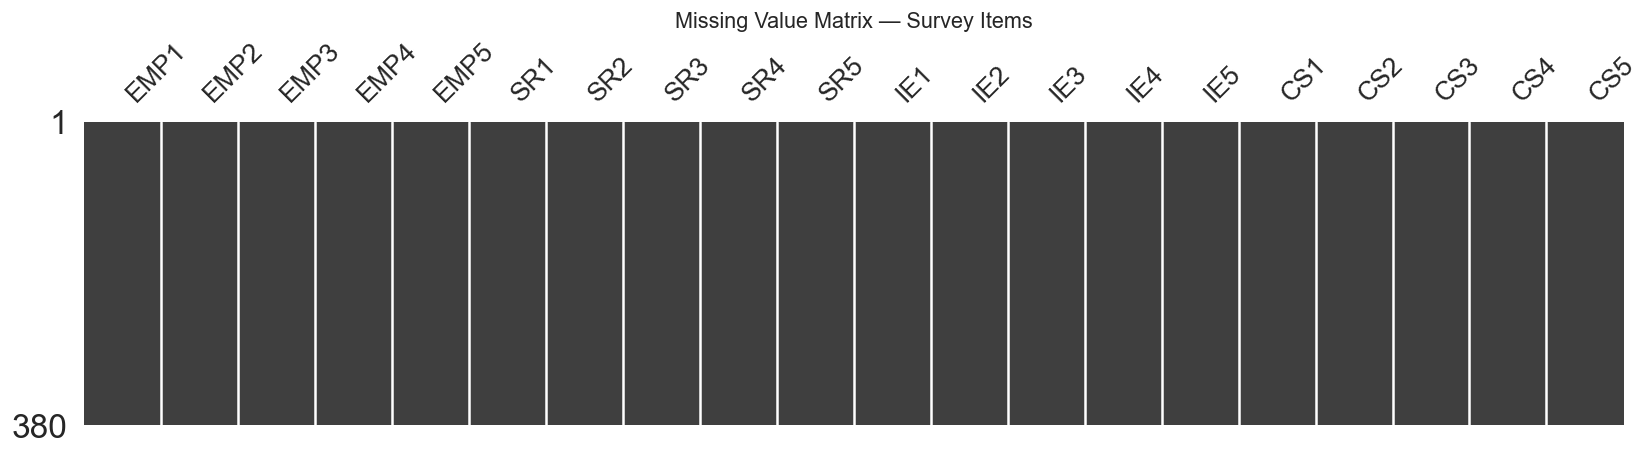


Missing % per construct item:
EMP1    0.0
EMP2    0.0
EMP3    0.0
EMP4    0.0
EMP5    0.0
SR1     0.0
SR2     0.0
SR3     0.0
SR4     0.0
SR5     0.0
IE1     0.0
IE2     0.0
IE3     0.0
IE4     0.0
IE5     0.0
CS1     0.0
CS2     0.0
CS3     0.0
CS4     0.0
CS5     0.0


In [7]:
# Missing value heatmap
fig, ax = plt.subplots(figsize=(14, 4))
msno.matrix(df[all_items], ax=ax, sparkline=False)
ax.set_title('Missing Value Matrix — Survey Items', fontsize=13)
plt.tight_layout()
plt.show()

# Missing % per construct
print('\nMissing % per construct item:')
print(df[all_items].isnull().mean().mul(100).round(2).to_string())

In [8]:
# Outlier check: Z-score > 3 on composite scores
z_scores = np.abs(stats.zscore(df[CONSTRUCTS].dropna()))
outliers = (z_scores > 3).sum(axis=0)
print('Potential outliers (|z| > 3) per construct:')
for c, n in zip(CONSTRUCTS, outliers):
    print(f'  {c}: {n}')

Potential outliers (|z| > 3) per construct:
  employability: 0
  skill_relevance: 0
  income_expect: 0
  career_sat: 3


---
## 4. Descriptive Statistics & Demographics

In [9]:
# Construct-level descriptives
desc = df[CONSTRUCTS].agg(['count','mean','std','min','max']).T
desc.columns = ['N', 'Mean', 'SD', 'Min', 'Max']
desc.round(3)

,N,Mean,SD,Min,Max
employability,380.0,3.972,0.483,3.0,5.0
skill_relevance,380.0,3.967,0.385,3.0,5.0
income_expect,380.0,4.276,0.451,3.0,5.0
career_sat,380.0,4.484,0.469,3.0,5.0


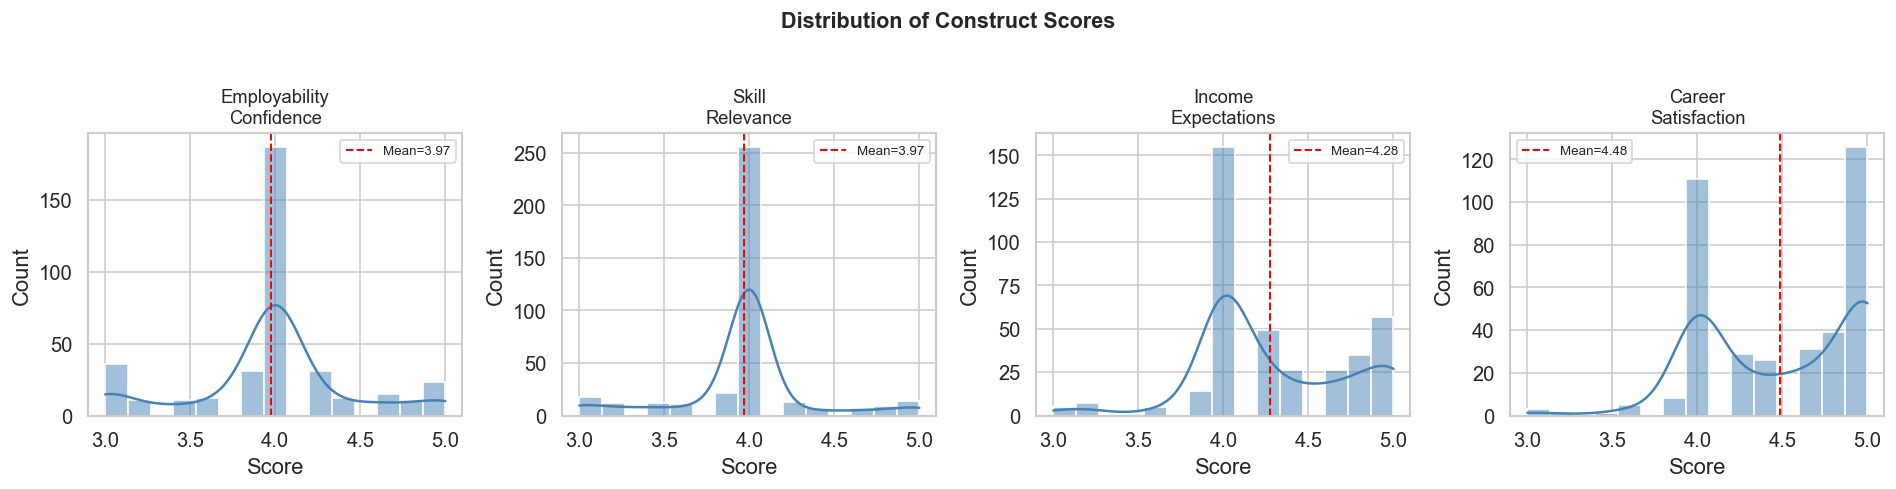

In [10]:
# Distribution plots for all constructs
fig, axes = plt.subplots(1, len(CONSTRUCTS), figsize=(4*len(CONSTRUCTS), 4))
labels = {'employability': 'Employability\nConfidence',
          'skill_relevance': 'Skill\nRelevance',
          'income_expect': 'Income\nExpectations',
          'social_mobility': 'Social\nMobility',
          'career_sat': 'Career\nSatisfaction'}

for ax, col in zip(axes, CONSTRUCTS):
    sns.histplot(df[col].dropna(), kde=True, ax=ax, color='steelblue', bins=15)
    ax.set_title(labels.get(col, col), fontsize=11)
    ax.set_xlabel('Score')
    ax.set_ylabel('Count')
    # Add mean line
    ax.axvline(df[col].mean(), color='red', linestyle='--', linewidth=1.2, label=f'Mean={df[col].mean():.2f}')
    ax.legend(fontsize=8)

plt.suptitle('Distribution of Construct Scores', y=1.02, fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

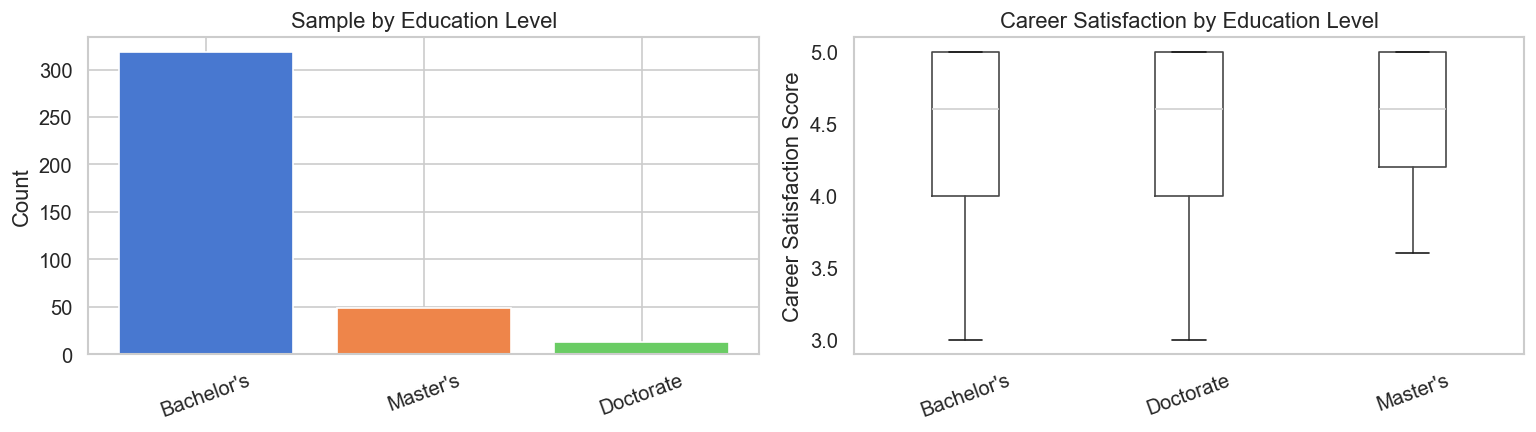

In [11]:
# Demographics
dem_col = DEMOGRAPHIC_COLS.get('edu_level')
if dem_col and dem_col in df.columns:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    # Education level counts
    edu_counts = df[dem_col].value_counts()
    axes[0].bar(edu_counts.index, edu_counts.values, color=sns.color_palette('muted', len(edu_counts)))
    axes[0].set_title('Sample by Education Level')
    axes[0].set_ylabel('Count')
    axes[0].tick_params(axis='x', rotation=20)

    # Career satisfaction by education level
    df.boxplot(column=DV, by=dem_col, ax=axes[1], grid=False)
    axes[1].set_title('Career Satisfaction by Education Level')
    axes[1].set_xlabel('')
    axes[1].set_ylabel('Career Satisfaction Score')
    axes[1].tick_params(axis='x', rotation=20)
    plt.suptitle('')

    plt.tight_layout()
    plt.show()
else:
    print('Education level column not found. Update DEMOGRAPHIC_COLS.')

---
## 5. Reliability Analysis — Cronbach's Alpha

In [12]:
def cronbach_alpha(df_items):
    """Calculate Cronbach's Alpha for a set of items."""
    df_clean = df_items.dropna()
    k = df_clean.shape[1]
    if k < 2:
        return np.nan
    item_vars = df_clean.var(axis=0, ddof=1)
    total_var = df_clean.sum(axis=1).var(ddof=1)
    alpha = (k / (k - 1)) * (1 - item_vars.sum() / total_var)
    return round(alpha, 3)

print('=== Reliability Analysis (Cronbach\'s Alpha) ===')
print(f'{"Construct":<20} {"Items":>6} {"Alpha":>8} {"Interpretation":>16}')
print('-' * 55)

for construct, items in CONSTRUCT_MAP.items():
    valid = [i for i in items if i in df.columns]
    if len(valid) >= 2:
        alpha = cronbach_alpha(df[valid])
        interp = 'Excellent' if alpha >= 0.9 else 'Good' if alpha >= 0.8 else \
                 'Acceptable' if alpha >= 0.7 else 'Questionable' if alpha >= 0.6 else 'Poor'
        print(f'{construct:<20} {len(valid):>6} {alpha:>8.3f} {interp:>16}')
    else:
        print(f'{construct:<20} {"N/A":>6} {"—":>8} {"Not enough items":>16}')

print('\nNote: α ≥ 0.70 is conventionally acceptable for social science research.')

=== Reliability Analysis (Cronbach's Alpha) ===
Construct             Items    Alpha   Interpretation
-------------------------------------------------------
employability             5    0.928        Excellent
skill_relevance           5    0.921        Excellent
income_expect             5    0.901        Excellent
career_sat                5    0.918        Excellent

Note: α ≥ 0.70 is conventionally acceptable for social science research.


---
## 6. Exploratory Factor Analysis (EFA)

In [13]:
# Bartlett's test + KMO before EFA
from factor_analyzer.factor_analyzer import calculate_bartlett_sphericity, calculate_kmo

item_data = df[all_items].dropna()

chi2, p = calculate_bartlett_sphericity(item_data)
kmo_all, kmo_model = calculate_kmo(item_data)

print(f'Bartlett\'s Test of Sphericity: χ² = {chi2:.2f}, p = {p:.4f}')
print(f'Kaiser-Meyer-Olkin (KMO): {kmo_model:.3f}')

if p < 0.05 and kmo_model >= 0.6:
    print('✓ Data is suitable for factor analysis.')
else:
    print('⚠ Data may not be suitable for factor analysis. Review items.')

Bartlett's Test of Sphericity: χ² = 5965.42, p = 0.0000
Kaiser-Meyer-Olkin (KMO): 0.960
✓ Data is suitable for factor analysis.


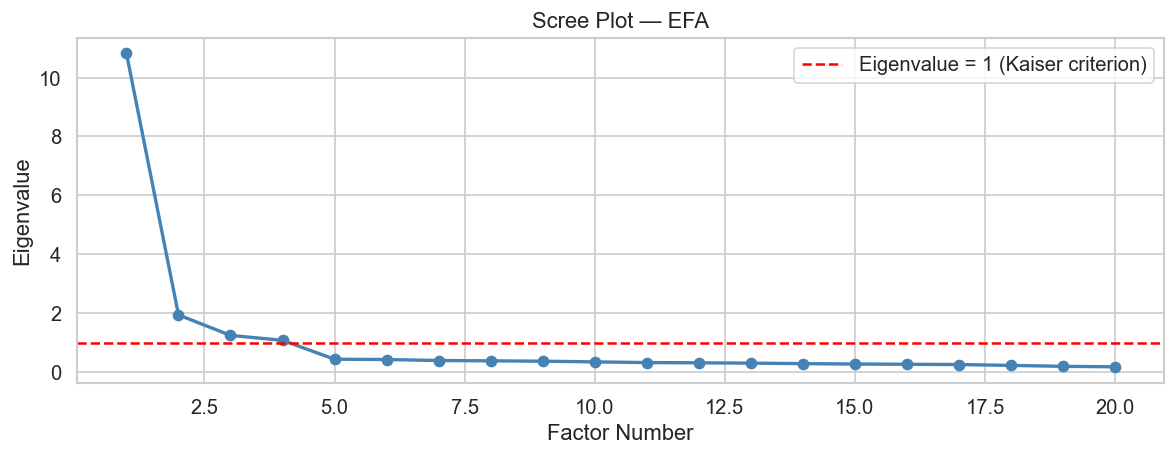

Number of factors with Eigenvalue > 1: 4


In [14]:
# Scree plot to determine number of factors
fa_eigen = FactorAnalyzer(n_factors=len(all_items), rotation=None)
fa_eigen.fit(item_data)
ev, v = fa_eigen.get_eigenvalues()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(range(1, len(ev)+1), ev, 'o-', color='steelblue', linewidth=2)
ax.axhline(1, color='red', linestyle='--', label='Eigenvalue = 1 (Kaiser criterion)')
ax.set_xlabel('Factor Number')
ax.set_ylabel('Eigenvalue')
ax.set_title('Scree Plot — EFA')
ax.legend()
plt.tight_layout()
plt.show()

n_factors_suggested = (ev > 1).sum()
print(f'Number of factors with Eigenvalue > 1: {n_factors_suggested}')

In [15]:
# EFA with the 4 theorized constructs
n_factors = len(CONSTRUCT_MAP)  # 4 constructs

fa = FactorAnalyzer(n_factors=n_factors, rotation='oblimin')  # oblimin for correlated factors
fa.fit(item_data)

loadings = pd.DataFrame(
    fa.loadings_,
    index=all_items,
    columns=[f'F{i+1}' for i in range(n_factors)]
)

print('=== Factor Loadings (|loading| ≥ 0.40 bolded in practice) ===')
print(loadings.round(3).to_string())

# Variance explained
variance = fa.get_factor_variance()
var_df = pd.DataFrame(variance, index=['SS Loadings', 'Proportion Var', 'Cumulative Var'],
                      columns=[f'F{i+1}' for i in range(n_factors)])
print('\n=== Variance Explained ===')
print(var_df.round(3))
print(f"\nPrimary loading range: {loadings.abs().max(axis=1).min():.3f} to {loadings.abs().max(axis=1).max():.3f}")


=== Factor Loadings (|loading| ≥ 0.40 bolded in practice) ===
         F1     F2     F3     F4
EMP1  0.816  0.040 -0.030  0.062
EMP2  0.848  0.024 -0.005  0.026
EMP3  0.841 -0.022  0.066 -0.066
EMP4  0.825  0.006  0.035  0.014
EMP5  0.790  0.006 -0.002  0.033
SR1  -0.021  0.853 -0.030  0.025
SR2  -0.001  0.871 -0.001  0.000
SR3  -0.020  0.833 -0.022  0.049
SR4   0.101  0.719  0.056 -0.047
SR5   0.006  0.845  0.042 -0.024
IE1  -0.049  0.062  0.051  0.772
IE2  -0.047 -0.015  0.145  0.749
IE3   0.035  0.034 -0.056  0.819
IE4   0.018  0.013  0.047  0.735
IE5   0.136 -0.042 -0.059  0.756
CS1   0.085  0.022  0.732 -0.015
CS2  -0.036 -0.006  0.866  0.030
CS3   0.107  0.007  0.710 -0.004
CS4  -0.000  0.058  0.841 -0.030
CS5  -0.014 -0.023  0.821  0.084

=== Variance Explained ===
                   F1     F2     F3     F4
SS Loadings     3.451  3.423  3.218  2.965
Proportion Var  0.173  0.171  0.161  0.148
Cumulative Var  0.173  0.344  0.505  0.653

Primary loading range: 0.710 to 0.871


---
## 7. Correlation Analysis

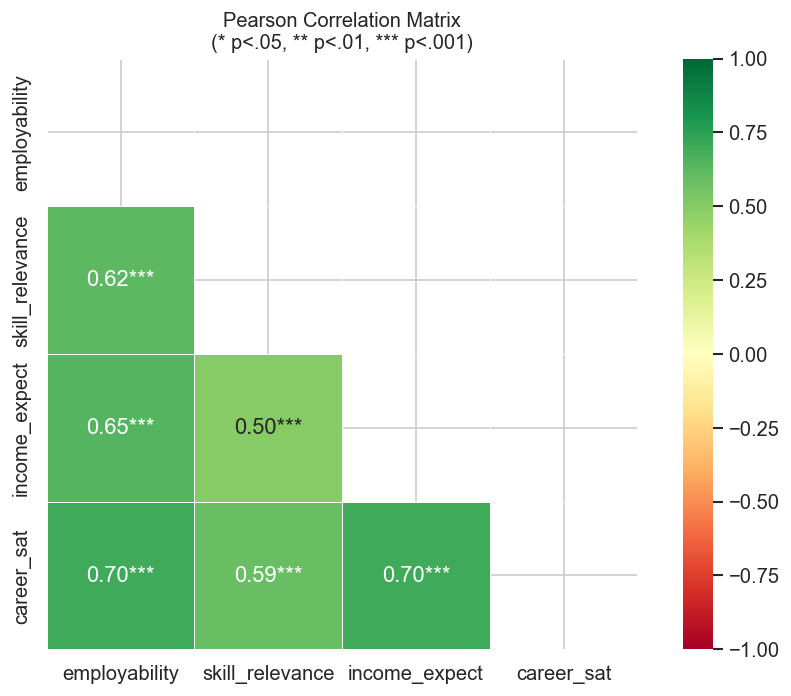

In [16]:
# Pearson correlation matrix among constructs
corr_df = df[CONSTRUCTS].dropna()
corr_matrix = corr_df.corr()

# p-values
from scipy.stats import pearsonr
p_matrix = pd.DataFrame(np.ones((len(CONSTRUCTS), len(CONSTRUCTS))),
                         index=CONSTRUCTS, columns=CONSTRUCTS)
for i in CONSTRUCTS:
    for j in CONSTRUCTS:
        if i != j:
            r, p = pearsonr(corr_df[i], corr_df[j])
            p_matrix.loc[i, j] = p

# Heatmap
fig, ax = plt.subplots(figsize=(8, 6))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
annot = corr_matrix.round(2).astype(str)
# Add significance stars
for i in CONSTRUCTS:
    for j in CONSTRUCTS:
        if i != j and not mask[CONSTRUCTS.index(i), CONSTRUCTS.index(j)]:
            p = p_matrix.loc[i, j]
            stars = '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else ''
            annot.loc[i, j] = f"{corr_matrix.loc[i, j]:.2f}{stars}"

sns.heatmap(corr_matrix, mask=mask, annot=annot, fmt='', cmap='RdYlGn',
            vmin=-1, vmax=1, center=0, ax=ax, square=True, linewidths=0.5)
ax.set_title('Pearson Correlation Matrix\n(* p<.05, ** p<.01, *** p<.001)', fontsize=12)
plt.tight_layout()
plt.show()

---
## 8. Multiple Regression Analysis

In [17]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

reg_data = df[CONSTRUCTS].dropna()
X = reg_data[IVs]
y = reg_data[DV]
X_const = sm.add_constant(X)

model = sm.OLS(y, X_const).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:             career_sat   R-squared:                       0.613
Model:                            OLS   Adj. R-squared:                  0.610
Method:                 Least Squares   F-statistic:                     198.3
Date:                Mon, 26 Oct 2026   Prob (F-statistic):           4.21e-77
Time:                        11:52:35   Log-Likelihood:                -70.949
No. Observations:                 380   AIC:                             149.9
Df Residuals:                     376   BIC:                             165.7
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const               0.5520      0.173     

In [18]:
# VIF check for multicollinearity
# NOTE: the intercept must be included when computing VIF with statsmodels'
# variance_inflation_factor; omitting it inflates the values enormously.
X_vif = sm.add_constant(X)
vif_data = pd.DataFrame()
vif_data['Variable'] = X_vif.columns
vif_data['VIF'] = [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
vif_data = vif_data[vif_data['Variable'] != 'const']  # drop the intercept row
print('\n=== Variance Inflation Factors (VIF) ===')
print(vif_data.round(3).to_string(index=False))
print('\nNote: VIF > 10 suggests problematic multicollinearity.')



=== Variance Inflation Factors (VIF) ===
       Variable   VIF
  employability 2.145
skill_relevance 1.663
  income_expect 1.766

Note: VIF > 10 suggests problematic multicollinearity.


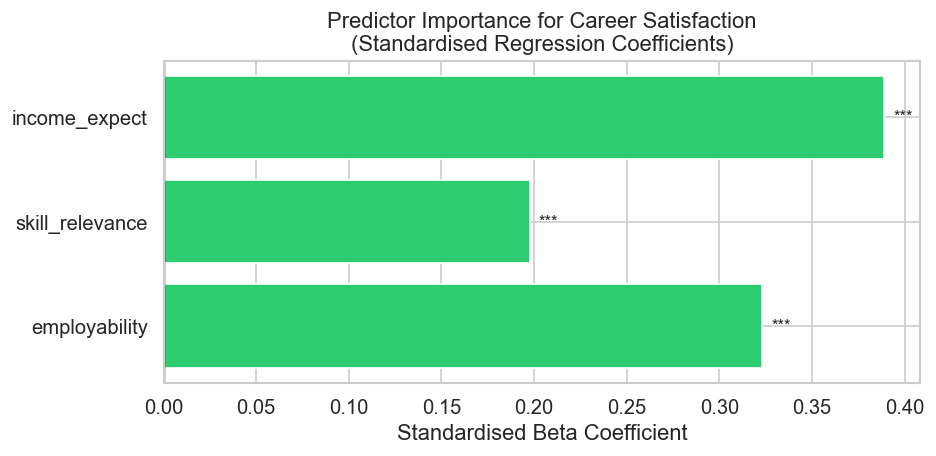


Model R² = 0.613, Adjusted R² = 0.610


In [19]:
# Standardised beta coefficients (for predictor importance comparison)
scaler = StandardScaler()
X_std = pd.DataFrame(scaler.fit_transform(X), columns=IVs)
y_std = pd.Series(scaler.fit_transform(y.values.reshape(-1,1)).flatten())

model_std = sm.OLS(y_std, sm.add_constant(X_std)).fit()
betas = model_std.params[1:]  # exclude constant
p_vals = model_std.pvalues[1:]

fig, ax = plt.subplots(figsize=(8, 4))
colors = ['#2ecc71' if b > 0 else '#e74c3c' for b in betas]
bars = ax.barh(IVs, betas, color=colors, edgecolor='white')
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Standardised Beta Coefficient')
ax.set_title('Predictor Importance for Career Satisfaction\n(Standardised Regression Coefficients)')
# Add p-value annotations
for bar, p in zip(bars, p_vals):
    stars = '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'ns'
    ax.text(bar.get_width() + 0.005, bar.get_y() + bar.get_height()/2,
            stars, va='center', fontsize=10)
plt.tight_layout()
plt.show()

print(f"\nModel R² = {model_std.rsquared:.3f}, Adjusted R² = {model_std.rsquared_adj:.3f}")

---
## 9. Structural Equation Modelling (SEM)

Using `semopy` for a path model where all three perceived educational return constructs predict career satisfaction.

In [20]:
# SEM model specification
# Measurement model: each construct is measured by its items
# Structural model: IVs → Career Satisfaction

def build_sem_model(construct_map):
    """Build semopy model string from construct map."""
    lines = []
    # Measurement model
    for construct, items in construct_map.items():
        valid = [i for i in items if i in df.columns]
        if valid:
            lines.append(f"{construct} =~ {' + '.join(valid)}")
    lines.append('')
    # Structural model
    ivs = [c for c in construct_map if c != 'career_sat']
    lines.append(f"career_sat ~ {' + '.join(ivs)}")
    return '\n'.join(lines)

model_spec = build_sem_model(CONSTRUCT_MAP)
print('=== SEM Model Specification ===')
print(model_spec)

=== SEM Model Specification ===
employability =~ EMP1 + EMP2 + EMP3 + EMP4 + EMP5
skill_relevance =~ SR1 + SR2 + SR3 + SR4 + SR5
income_expect =~ IE1 + IE2 + IE3 + IE4 + IE5
career_sat =~ CS1 + CS2 + CS3 + CS4 + CS5

career_sat ~ employability + skill_relevance + income_expect


In [21]:
# Fit SEM
sem_data = df[all_items].dropna()
sem_model = semopy.Model(model_spec)
res = sem_model.fit(sem_data)

stats_sem = semopy.calc_stats(sem_model)

# SRMR (not provided by semopy): RMS of residual correlations, lower triangle incl. diagonal
obs = sem_model.vars['observed']
S = sem_data[obs].cov(ddof=0).values
Sigma = sem_model.calc_sigma()[0]
d = np.sqrt(np.diag(S))
resid = (S - Sigma) / np.outer(d, d)
srmr = np.sqrt(np.mean(resid[np.tril_indices(len(obs))] ** 2))

fit_indices = pd.DataFrame({
    'Value': [stats_sem['chi2'].iloc[0], stats_sem['DoF'].iloc[0], stats_sem['chi2 p-value'].iloc[0],
              stats_sem['chi2'].iloc[0] / stats_sem['DoF'].iloc[0],
              stats_sem['CFI'].iloc[0], stats_sem['TLI'].iloc[0], stats_sem['RMSEA'].iloc[0], srmr],
    'Threshold': ['—', '—', '> .05', '< 3', '≥ .95', '≥ .95', '≤ .06', '≤ .08'],
}, index=['χ²', 'df', 'p-value', 'χ²/df', 'CFI', 'TLI', 'RMSEA', 'SRMR'])
print(f'=== SEM Fit Statistics (N = {len(sem_data)}) ===')
print(fit_indices.round(3).to_string())


=== SEM Fit Statistics (N = 380) ===
           Value Threshold
χ²       169.808         —
df       164.000         —
p-value    0.362     > .05
χ²/df      1.035       < 3
CFI        0.999     ≥ .95
TLI        0.999     ≥ .95
RMSEA      0.010     ≤ .06
SRMR       0.021     ≤ .08


In [22]:
# Path coefficients: 'Estimate' is unstandardized (B); 'Est. Std' is the standardized coefficient (β)
params = sem_model.inspect(std_est=True)
print('\n=== SEM Parameter Estimates ===')
print(params.round(3).to_string())

structural_paths = params[(params['op'] == '~') & (params['lval'] == 'career_sat')]
print('\n=== Structural paths to career satisfaction ===')
print(structural_paths[['rval', 'Estimate', 'Est. Std', 'Std. Err', 'z-value', 'p-value']].round(3).to_string(index=False))



=== SEM Parameter Estimates ===
               lval  op             rval  Estimate  Est. Std  Std. Err    z-value   p-value
0        career_sat   ~    employability     0.282     0.309  0.056938   4.944501  0.000001
1        career_sat   ~  skill_relevance     0.235     0.188  0.062894   3.739786  0.000184
2        career_sat   ~    income_expect     0.457     0.447  0.060295   7.584175       0.0
3              EMP1   ~    employability     1.000     0.862         -          -         -
4              EMP2   ~    employability     1.052     0.881  0.045457  23.151715       0.0
5              EMP3   ~    employability     0.932     0.824  0.045357  20.547925       0.0
6              EMP4   ~    employability     0.992     0.863  0.044502  22.302428       0.0
7              EMP5   ~    employability     0.913     0.815  0.045244  20.168907       0.0
8               SR1   ~  skill_relevance     1.000     0.828         -          -         -
9               SR2   ~  skill_relevance     1.

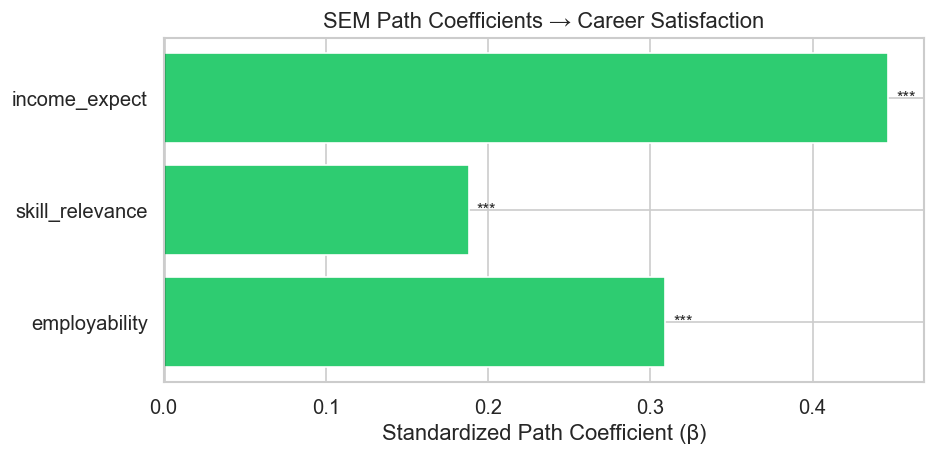

In [23]:
# First, ensure the 'p-value' column in params is numeric, coercing errors
params['p-value'] = pd.to_numeric(params['p-value'], errors='coerce')

# Visualise structural paths (career_sat as outcome)
structural = params[params['op'] == '~'].copy()
structural = structural[structural['lval'] == 'career_sat']

if not structural.empty:
    fig, ax = plt.subplots(figsize=(8, 4))
    colors = ['#2ecc71' if e > 0 else '#e74c3c' for e in structural['Est. Std']]
    bars = ax.barh(structural['rval'], structural['Est. Std'], color=colors)
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_xlabel('Standardized Path Coefficient (β)')
    ax.set_title('SEM Path Coefficients → Career Satisfaction')
    # Significance markers
    for bar, (_, row) in zip(bars, structural.iterrows()):
        p = row.get('p-value', np.nan) # p should now be numeric or NaN
        if pd.notna(p):
            stars = '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'ns'
            ax.text(bar.get_width() + 0.005, bar.get_y() + bar.get_height()/2,
                    stars, va='center', fontsize=10)
    plt.tight_layout()
    plt.show()
else:
    print('No structural paths found. Verify column names match CONSTRUCT_MAP.')

---
## 10. Subgroup Analysis — Education Level

In [24]:
edu_col = DEMOGRAPHIC_COLS.get('edu_level')

if edu_col and edu_col in df.columns:
    # One-Way ANOVA: Career satisfaction across education levels
    anova_result = pg.anova(data=df, dv=DV, between=edu_col, detailed=True)
    print('=== ANOVA: Career Satisfaction by Education Level ===')
    print(anova_result.round(4).to_string())

    if anova_result['p_unc'].values[0] < 0.05:
        print('\n→ Significant difference found. Running post-hoc Tukey HSD...')
        posthoc = pg.pairwise_tukey(data=df.dropna(subset=[DV, edu_col]),
                                     dv=DV, between=edu_col)
        print(posthoc.round(4).to_string())
else:
    print('Education level column not configured. Update DEMOGRAPHIC_COLS.')

=== ANOVA: Career Satisfaction by Education Level ===
           Source       SS   DF      MS       F   p_unc     np2
0  EducationLevel   0.1943    2  0.0972  0.4398  0.6445  0.0023
1          Within  83.2710  377  0.2209     NaN     NaN     NaN


---
## 11. Expectation–Reality Gap Analysis

This section analyses the gap between income expectations and career satisfaction — a key theme in the abstract.

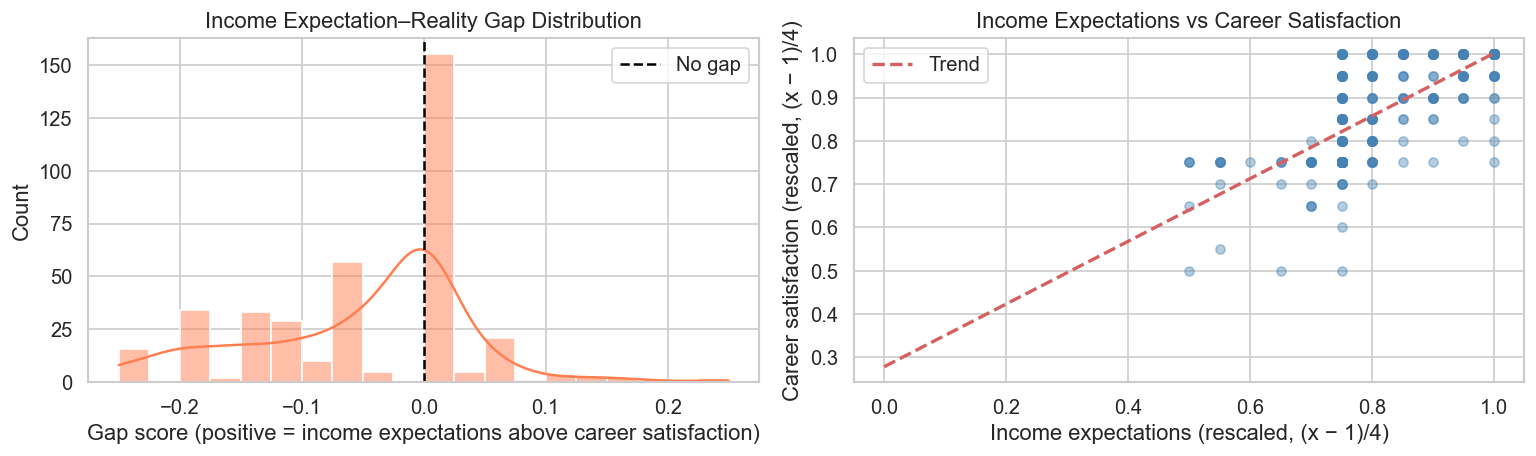

Gap = (income expectations - 1)/4 - (career satisfaction - 1)/4
Mean gap score: -0.052 (SD 0.090)
Respondents with income expectations above career satisfaction (gap > 0): 39 (10.3%)


In [25]:
# Gap score: high income expectations but low career satisfaction = large gap
gap_data = df[['income_expect', 'career_sat', 'skill_relevance', 'employability']].dropna()

# Rescale to 0-1 using the theoretical range of the five-point scale: (x - 1) / 4
# (does not depend on the sample's observed minimum and maximum)
gap_norm = (gap_data - 1) / 4

gap_norm['expectation_gap'] = gap_norm['income_expect'] - gap_norm['career_sat']

# Histogram of gap scores
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(gap_norm['expectation_gap'], kde=True, ax=axes[0], color='coral', bins=20)
axes[0].axvline(0, color='black', linestyle='--', linewidth=1.5, label='No gap')
axes[0].set_title('Income Expectation–Reality Gap Distribution')
axes[0].set_xlabel('Gap score (positive = income expectations above career satisfaction)')
axes[0].legend()

# Scatter: income expectations vs career satisfaction
axes[1].scatter(gap_norm['income_expect'], gap_norm['career_sat'],
                alpha=0.4, color='steelblue', s=30)
z = np.polyfit(gap_norm['income_expect'], gap_norm['career_sat'], 1)
p = np.poly1d(z)
x_line = np.linspace(0, 1, 100)
axes[1].plot(x_line, p(x_line), 'r--', linewidth=2, label='Trend')
axes[1].set_xlabel('Income expectations (rescaled, (x − 1)/4)')
axes[1].set_ylabel('Career satisfaction (rescaled, (x − 1)/4)')
axes[1].set_title('Income Expectations vs Career Satisfaction')
axes[1].legend()

plt.tight_layout()
plt.show()

print('Gap = (income expectations - 1)/4 - (career satisfaction - 1)/4')
print(f"Mean gap score: {gap_norm['expectation_gap'].mean():.3f} (SD {gap_norm['expectation_gap'].std():.3f})")
print(f"Respondents with income expectations above career satisfaction (gap > 0): {(gap_norm['expectation_gap'] > 0).sum()} ({(gap_norm['expectation_gap'] > 0).mean()*100:.1f}%)")

---
## 12. Robustness Checks

Every item response lies between 3 (Neutral) and 5 (Strongly Agree). These checks confirm the regression
results are not an artefact of that restricted range or of the three career-satisfaction outliers.

In [26]:
# Response range across all 20 items
values = pd.Series(df[all_items].values.ravel())
print('Response distribution across all items:', values.value_counts().sort_index().to_dict())
print(f'Responses of 1 or 2 (Disagree / Strongly Disagree): {(values < 3).sum()}')


Response distribution across all items: {3: 649, 4: 4974, 5: 1977}
Responses of 1 or 2 (Disagree / Strongly Disagree): 0


In [27]:
def std_betas(data):
    z = (data - data.mean()) / data.std()
    return sm.OLS(z[DV], sm.add_constant(z[IVs])).fit()

# 1. Outlier sensitivity: drop cases with |z| > 3 on any composite
keep = (np.abs(stats.zscore(df[CONSTRUCTS])) <= 3).all(axis=1)
for label, data in [('All cases', df[CONSTRUCTS]), ('Outliers removed', df.loc[keep, CONSTRUCTS])]:
    fit = std_betas(data)
    print(f"{label:<17} n={len(data)}  R²={fit.rsquared:.3f}  β:", fit.params[IVs].round(3).to_dict())


All cases         n=380  R²=0.613  β: {'employability': 0.323, 'skill_relevance': 0.198, 'income_expect': 0.389}
Outliers removed  n=377  R²=0.602  β: {'employability': 0.309, 'skill_relevance': 0.197, 'income_expect': 0.4}


In [28]:
# 2. Percentile bootstrap 95% CIs for standardized betas (2,000 resamples, fixed seed)
rng = np.random.default_rng(42)
boot = np.array([std_betas(df[CONSTRUCTS].iloc[rng.integers(0, len(df), len(df))]).params[IVs].values
                 for _ in range(2000)])
lo, hi = np.percentile(boot, [2.5, 97.5], axis=0)
base = std_betas(df[CONSTRUCTS]).params[IVs]
print('Bootstrap 95% CIs for standardized betas:')
for name, b, l, h in zip(IVs, base, lo, hi):
    print(f'  {name:<16} β = {b:.3f}  [{l:.3f}, {h:.3f}]')


Bootstrap 95% CIs for standardized betas:
  employability    β = 0.323  [0.239, 0.406]
  skill_relevance  β = 0.198  [0.135, 0.256]
  income_expect    β = 0.389  [0.310, 0.465]


In [29]:
# 3. Rank-based correlations and heteroskedasticity-robust (HC3) standard errors
print('Spearman ρ with career satisfaction:', df[CONSTRUCTS].corr('spearman')[DV].drop(DV).round(3).to_dict())
hc3 = sm.OLS(df[DV], sm.add_constant(df[IVs])).fit(cov_type='HC3')
print(pd.DataFrame({'B': hc3.params, 'HC3 SE': hc3.bse, 't': hc3.tvalues, 'p': hc3.pvalues}).round(4).to_string())


Spearman ρ with career satisfaction: {'employability': 0.735, 'skill_relevance': 0.636, 'income_expect': 0.733}
                      B  HC3 SE       t       p
const            0.5520  0.1583  3.4865  0.0005
employability    0.3138  0.0400  7.8485  0.0000
skill_relevance  0.2410  0.0404  5.9636  0.0000
income_expect    0.4046  0.0421  9.6173  0.0000


---
## 13. Summary Dashboard — Key Findings

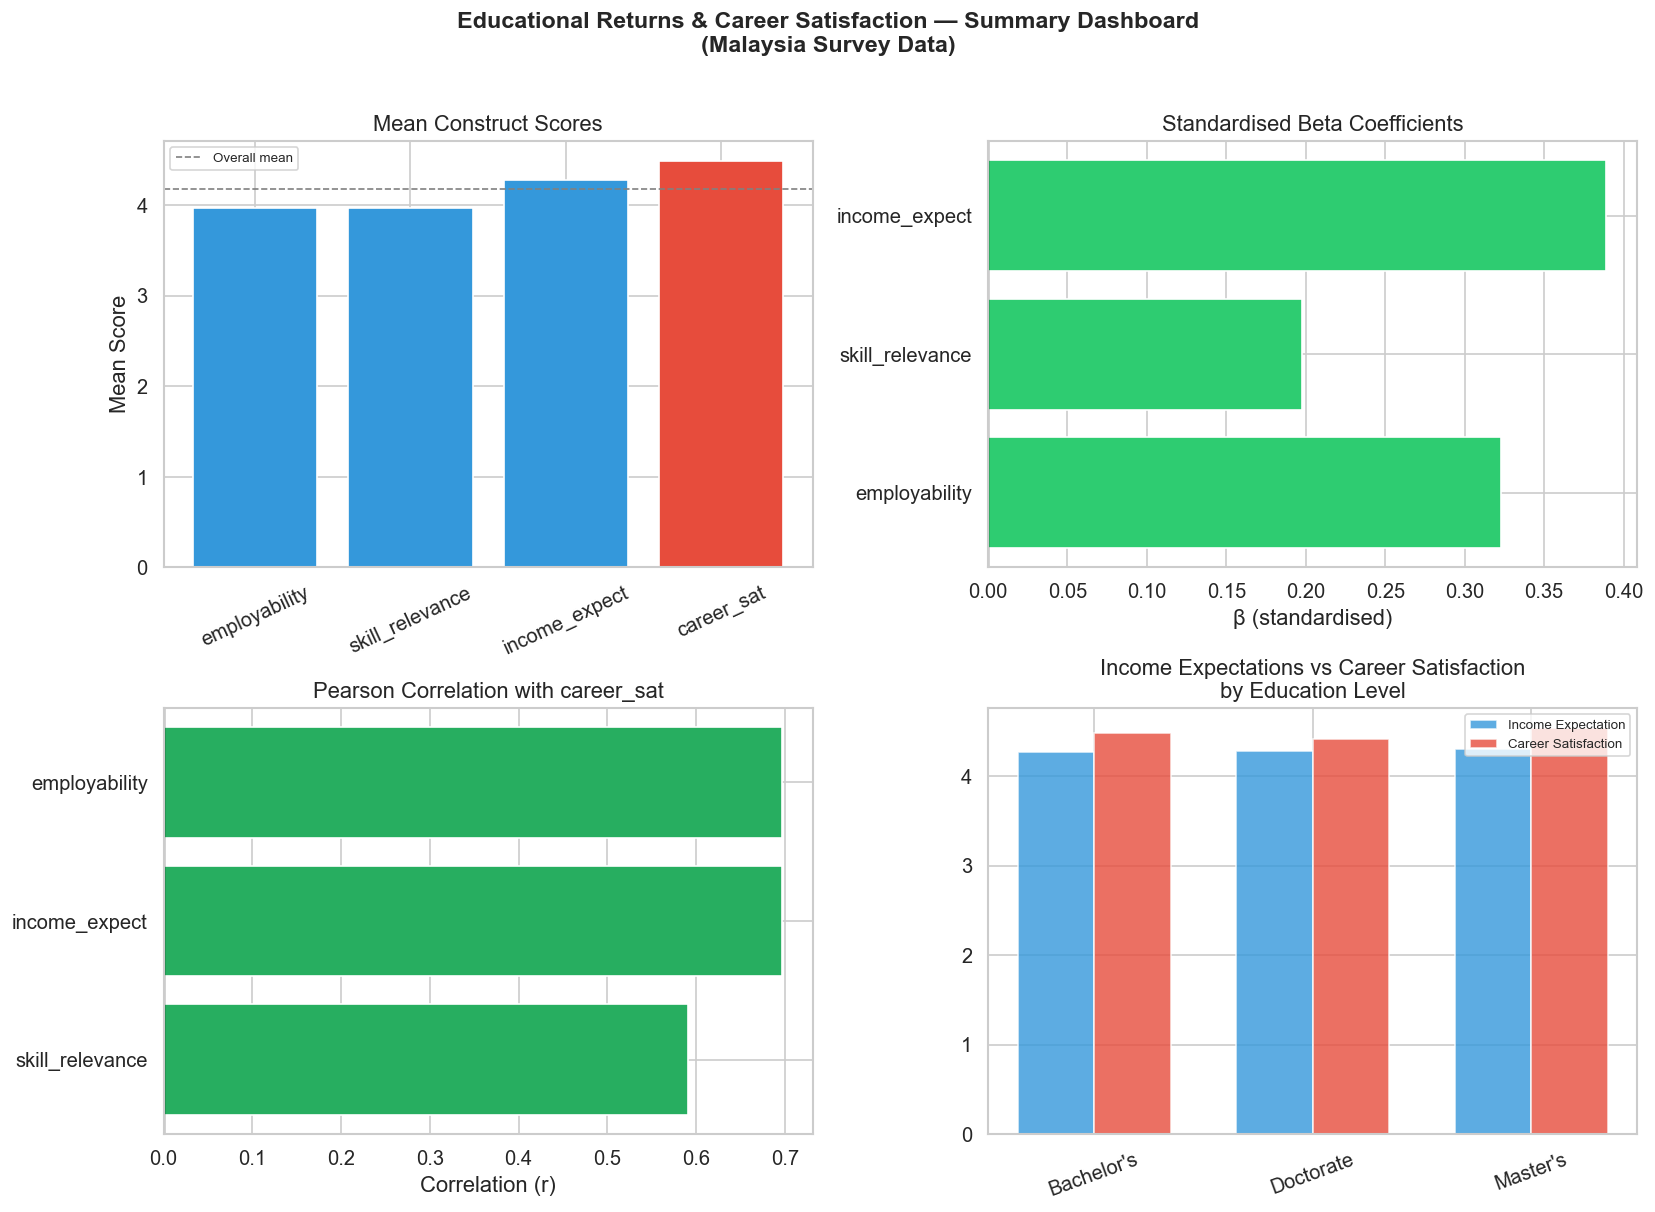

In [30]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Educational Returns & Career Satisfaction — Summary Dashboard\n(Malaysia Survey Data)',
             fontsize=14, fontweight='bold', y=1.01)

# 1. Mean construct scores
ax1 = axes[0, 0]
means = df[CONSTRUCTS].mean()
bar_colors = ['#3498db']*len(IVs) + ['#e74c3c']
ax1.bar(means.index, means.values, color=bar_colors, edgecolor='white')
ax1.set_title('Mean Construct Scores')
ax1.set_ylabel('Mean Score')
ax1.tick_params(axis='x', rotation=25)
ax1.axhline(means.mean(), color='gray', linestyle='--', linewidth=1, label='Overall mean')
ax1.legend(fontsize=8)

# 2. Standardised betas from regression
ax2 = axes[0, 1]
try:
    beta_vals = betas.values
    ax2.barh(IVs, beta_vals, color=['#2ecc71' if b>0 else '#e74c3c' for b in beta_vals])
    ax2.axvline(0, color='black', linewidth=0.8)
    ax2.set_title('Standardised Beta Coefficients')
    ax2.set_xlabel('β (standardised)')
except:
    ax2.text(0.5, 0.5, 'Run regression cell first', ha='center', va='center')

# 3. Correlation with career satisfaction
ax3 = axes[1, 0]
corr_with_dv = df[CONSTRUCTS].corr()[DV].drop(DV).sort_values(ascending=True)
ax3.barh(corr_with_dv.index, corr_with_dv.values,
         color=['#27ae60' if v > 0 else '#c0392b' for v in corr_with_dv.values])
ax3.set_title(f'Pearson Correlation with {DV}')
ax3.set_xlabel('Correlation (r)')
ax3.axvline(0, color='black', linewidth=0.8)

# 4. Expectation gap by education level
ax4 = axes[1, 1]
edu_col = DEMOGRAPHIC_COLS.get('edu_level')
if edu_col and edu_col in df.columns:
    gap_by_edu = df.groupby(edu_col)[['income_expect', 'career_sat']].mean()
    x = np.arange(len(gap_by_edu))
    width = 0.35
    ax4.bar(x - width/2, gap_by_edu['income_expect'], width, label='Income Expectation', color='#3498db', alpha=0.8)
    ax4.bar(x + width/2, gap_by_edu['career_sat'], width, label='Career Satisfaction', color='#e74c3c', alpha=0.8)
    ax4.set_xticks(x)
    ax4.set_xticklabels(gap_by_edu.index, rotation=20)
    ax4.set_title('Income Expectations vs Career Satisfaction\nby Education Level')
    ax4.legend(fontsize=8)
else:
    ax4.text(0.5, 0.5, 'Education level column\nnot configured', ha='center', va='center')

plt.tight_layout()
plt.show()

---
## 14. Export Results

In [31]:
with pd.ExcelWriter('analysis_results.xlsx', engine='openpyxl') as writer:
    # Descriptives
    df[CONSTRUCTS].describe().round(3).to_excel(writer, sheet_name='Descriptives')

    # Correlations
    corr_matrix.round(3).to_excel(writer, sheet_name='Correlations')

    # Regression
    model.summary2().tables[1].to_excel(writer, sheet_name='Regression')

    # SEM fit indices
    fit_indices.round(3).to_excel(writer, sheet_name='SEM_Fit')

    # SEM params
    try:
        params.round(3).to_excel(writer, sheet_name='SEM_Paths', index=False)
    except:
        pass

print('Results exported to analysis_results.xlsx')

Results exported to analysis_results.xlsx


Saved figure2_expectation_gap.png | N=380 | mean=-0.052 | below=186 zero=155 above=39 (10.3%)


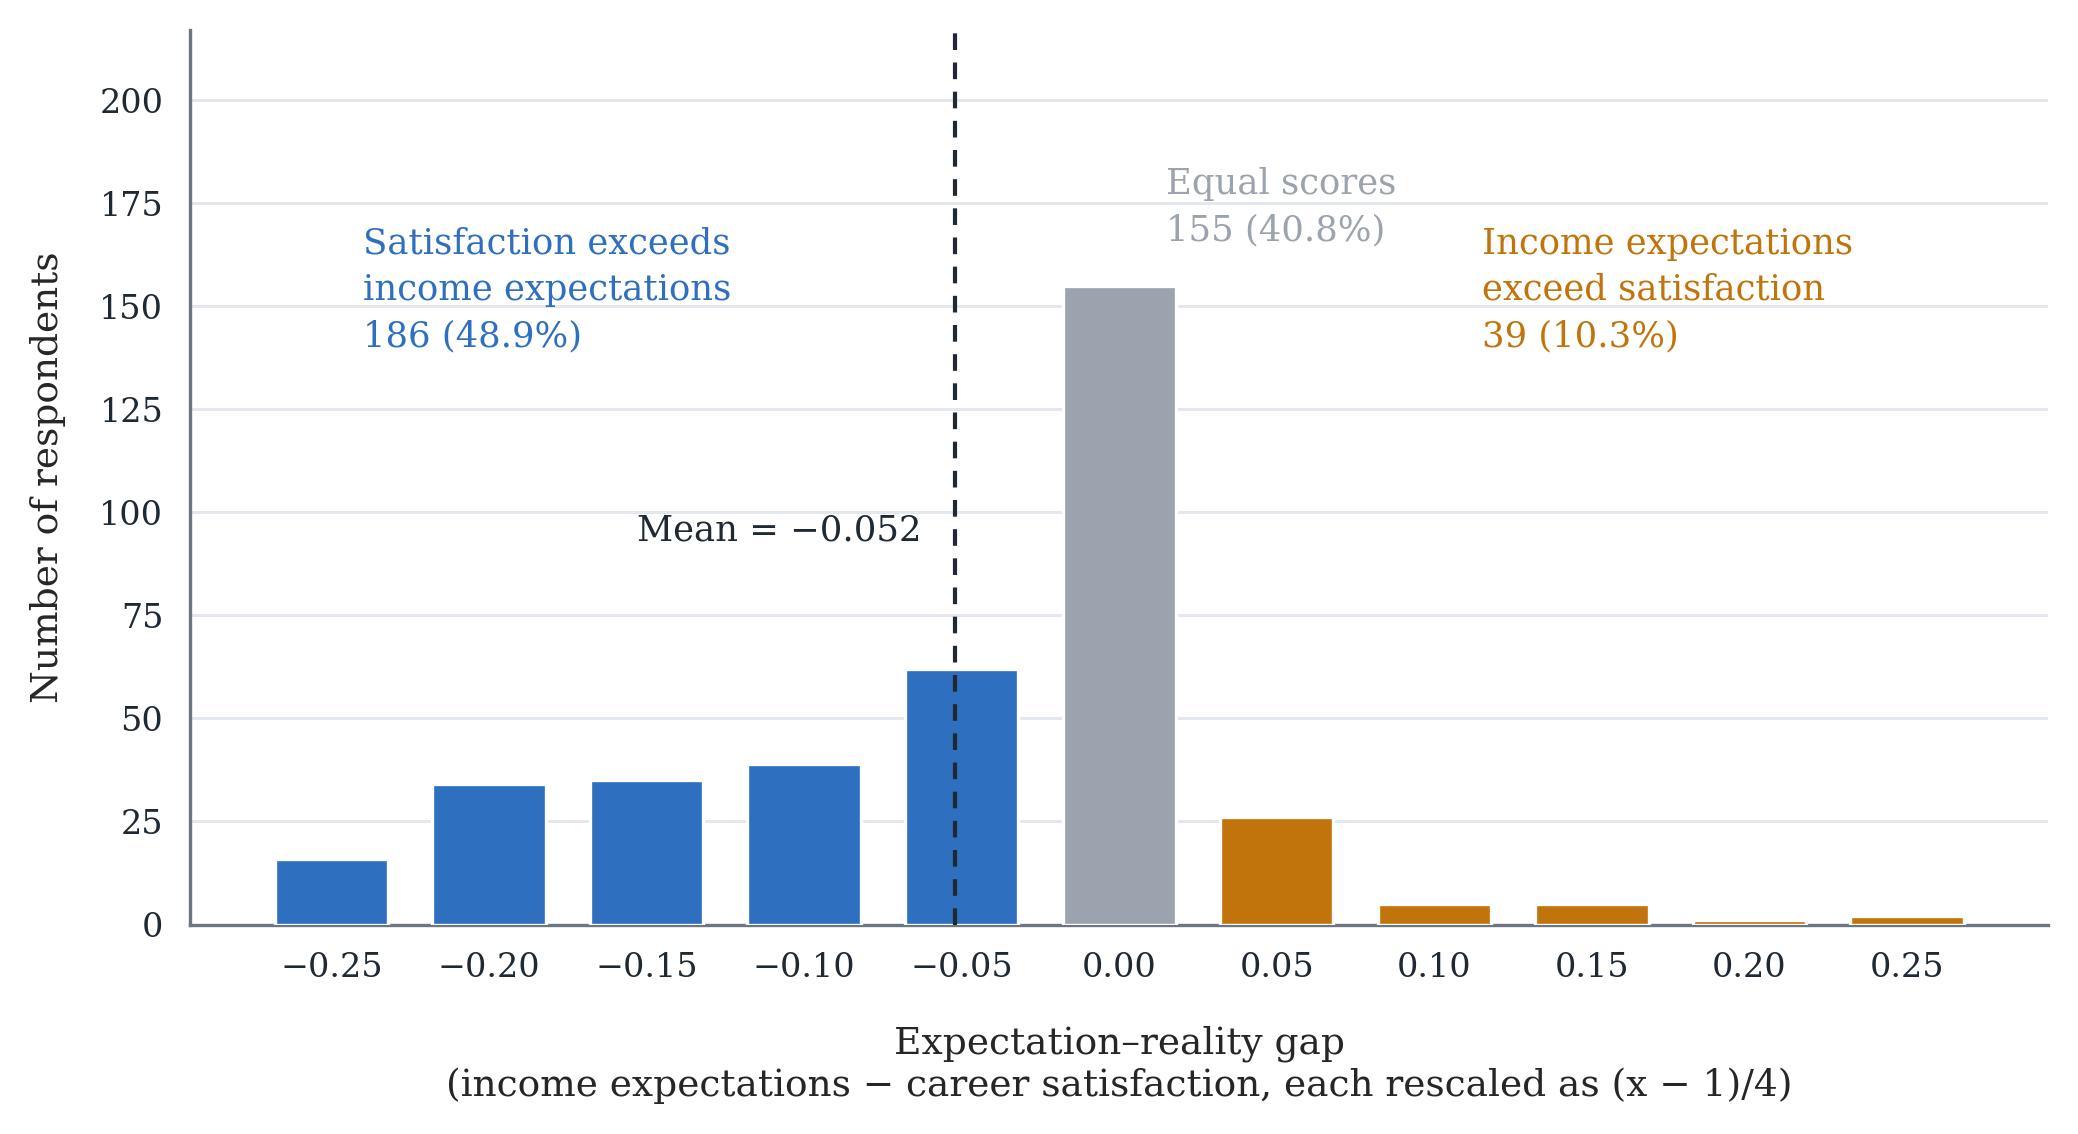

In [32]:
# ==============================================================================
# Figure 2 — Distribution of the expectation–reality gap
# Paste as a new cell in edu_return_analysis.ipynb (after Section 11), or run
# standalone. Saves figure2_expectation_gap.png at 300 dpi for insertion in Word.
# ==============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

FILE_PATH = 'edu_return_data.xlsx'          # adjust if your path differs
OUT_PATH  = 'figure2_expectation_gap.png'

CONSTRUCT_MAP = {
    'income_expect': ['IE1', 'IE2', 'IE3', 'IE4', 'IE5'],
    'career_sat':    ['CS1', 'CS2', 'CS3', 'CS4', 'CS5'],
}

df = pd.read_excel(FILE_PATH, sheet_name=0)
df = df[df['AgeGroup'] != 'Below 18'].reset_index(drop=True)   # exclude respondents below 18
for construct, items in CONSTRUCT_MAP.items():
    df[construct] = df[items].mean(axis=1)

# Gap = rescaled income expectations − rescaled career satisfaction, theoretical range (x − 1)/4
cols = ['income_expect', 'career_sat']
norm = (df[cols] - 1) / 4
gap  = (norm['income_expect'] - norm['career_sat']).round(6)

counts   = gap.value_counts().sort_index()
mean_gap = gap.mean()
n_below, n_zero, n_above = (gap < 0).sum(), (gap == 0).sum(), (gap > 0).sum()
N = len(gap)
# ---- styling -----------------------------------------------------------------
BLUE, GREY, AMBER = '#2F6FBF', '#9AA3AE', '#C2740C'
INK, MUTED, GRID  = '#1F2933', '#6B7682', '#E3E7EE'

plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 9,
    'axes.edgecolor': MUTED,
    'axes.linewidth': 0.8,
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
})

# Slightly larger figure
fig, ax = plt.subplots(figsize=(7.2, 4.2), dpi=300)

colors = [
    BLUE if v < 0 else (GREY if v == 0 else AMBER)
    for v in counts.index
]

ax.bar(
    counts.index,
    counts.values,
    width=0.036,
    color=colors,
    edgecolor='white',
    linewidth=0.8,
    zorder=3
)

# Mean line
ax.axvline(
    mean_gap,
    color=INK,
    lw=1.0,
    ls=(0, (4, 3)),
    zorder=4
)

# Give the annotations more vertical space
ax.set_ylim(0, counts.max() * 1.40)
ymax = ax.get_ylim()[1]

# ------------------------------------------------------------------
# Annotations
# ------------------------------------------------------------------

ax.text(
    -0.24,
    ymax * 0.78,
    f'Satisfaction exceeds\nincome expectations\n'
    f'{n_below} ({n_below/N*100:.1f}%)',
    color=BLUE,
    fontsize=8.5,
    va='top',
    ha='left',
    linespacing=1.45
)

ax.text(
    0.015,
    counts.max() * 1.06,
    f'Equal scores\n{n_zero} ({n_zero/N*100:.1f}%)',
    color=GREY,
    fontsize=8.5,
    va='bottom',
    ha='left',
    linespacing=1.45
)

ax.text(
    0.115,
    ymax * 0.78,
    f'Income expectations\nexceed satisfaction\n'
    f'{n_above} ({n_above/N*100:.1f}%)',
    color=AMBER,
    fontsize=8.5,
    va='top',
    ha='left',
    linespacing=1.45
)

# Mean annotation
ax.annotate(
    'Mean = ' + f'{mean_gap:.3f}'.replace('-', '\u2212'),
    xy=(mean_gap, ymax * 0.44),
    xytext=(-8, 0),
    textcoords='offset points',
    ha='right',
    va='center',
    fontsize=8.5,
    color=INK
)

# ------------------------------------------------------------------
# Axes
# ------------------------------------------------------------------

ax.set_xlabel(
    'Expectation–reality gap\n'
    '(income expectations − career satisfaction, each rescaled as (x − 1)/4)',
    labelpad=10,
    fontsize=9
)

ax.set_ylabel(
    'Number of respondents',
    labelpad=8,
    fontsize=9
)

ticks = np.round(np.arange(-0.25, 0.251, 0.05), 2)

ax.set_xticks(ticks)
ax.set_xticklabels([
    ('0.00' if abs(t) < 1e-9 else f'{t:.2f}').replace('-', '\u2212')
    for t in ticks
])

ax.yaxis.grid(
    True,
    color=GRID,
    lw=0.7,
    zorder=0
)

ax.xaxis.grid(False)
ax.tick_params(axis='both', labelsize=8)
ax.set_axisbelow(True)

for side in ('top', 'right'):
    ax.spines[side].set_visible(False)

ax.tick_params(
    colors=MUTED,
    length=3
)

for lbl in ax.get_xticklabels() + ax.get_yticklabels():
    lbl.set_color(INK)

# Give the two-line xlabel enough room
fig.subplots_adjust(
    left=0.11,
    right=0.97,
    top=0.94,
    bottom=0.23
)

fig.savefig(
    OUT_PATH,
    dpi=300,
    bbox_inches='tight',
    pad_inches=0.15,
    facecolor='white'
)
print(
    f'Saved {OUT_PATH} | N={N} | mean={mean_gap:.3f} | '
    f'below={n_below} zero={n_zero} above={n_above} '
    f'({n_above/N*100:.1f}%)'
)

plt.show()

In [33]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy.stats import norm as med_norm

med_file  = 'edu_return_data.xlsx'
med_nboot = 5000
med_seed  = 42
med_items = {
    'employability':   ['EMP1', 'EMP2', 'EMP3', 'EMP4', 'EMP5'],
    'skill_relevance': ['SR1', 'SR2', 'SR3', 'SR4', 'SR5'],
    'income_expect':   ['IE1', 'IE2', 'IE3', 'IE4', 'IE5'],
    'career_sat':      ['CS1', 'CS2', 'CS3', 'CS4', 'CS5'],
}
med_raw  = pd.read_excel(med_file, sheet_name=0)
med_raw = med_raw[med_raw['AgeGroup'] != 'Below 18'].reset_index(drop=True)   # exclude respondents below 18
med_data = pd.DataFrame({c: med_raw[items].mean(axis=1) for c, items in med_items.items()}).dropna().reset_index(drop=True)
med_M, med_Y = 'employability', 'career_sat'

def med_ols(y, xs, d):
    return sm.OLS(d[y], sm.add_constant(d[xs])).fit()

def med_indirect(d, X, cov):
    a = med_ols(med_M, [X, cov], d).params[X]
    b = med_ols(med_Y, [X, med_M, cov], d).params[med_M]
    return a * b

def med_bc_ci(boot, est, alpha=0.05):
    z0 = med_norm.ppf((boot < est).mean())
    lo = med_norm.cdf(2 * z0 + med_norm.ppf(alpha / 2))
    hi = med_norm.cdf(2 * z0 + med_norm.ppf(1 - alpha / 2))
    return np.percentile(boot, [lo * 100, hi * 100])

def med_run():
    med_paths, med_effects = [], []
    for X, cov in [('skill_relevance', 'income_expect'), ('income_expect', 'skill_relevance')]:
        a_fit = med_ols(med_M, [X, cov], med_data)            # path a
        y_fit = med_ols(med_Y, [X, med_M, cov], med_data)     # paths b and c' (same as Table 5)
        c_fit = med_ols(med_Y, [X, cov], med_data)            # total effect c
        ind = a_fit.params[X] * y_fit.params[med_M]

        rng = np.random.default_rng(med_seed)
        n = len(med_data)
        boot = np.array([med_indirect(med_data.iloc[rng.integers(0, n, n)], X, cov) for _ in range(med_nboot)])
        bc_lo, bc_hi = med_bc_ci(boot, ind)
        pc_lo, pc_hi = np.percentile(boot, [2.5, 97.5])

        for label, fit, var in [(f'a: {X} -> {med_M}', a_fit, X), (f'b: {med_M} -> {med_Y}', y_fit, med_M),
                                (f"c': {X} -> {med_Y} (direct)", y_fit, X), (f'c: {X} -> {med_Y} (total)', c_fit, X)]:
            ci = fit.conf_int().loc[var]
            med_paths.append({'Model': f'X = {X}', 'Path': label, 'B': fit.params[var], 'SE': fit.bse[var],
                              't': fit.tvalues[var], 'p': fit.pvalues[var], 'LLCI': ci[0], 'ULCI': ci[1]})
        med_effects.append({'X': X, 'Covariate': cov, 'a': a_fit.params[X], 'b': y_fit.params[med_M],
                            'Indirect (a*b)': ind, 'BootSE': boot.std(ddof=1),
                            'BC LLCI': bc_lo, 'BC ULCI': bc_hi, 'Pct LLCI': pc_lo, 'Pct ULCI': pc_hi,
                            'Std. indirect': ind * med_data[X].std() / med_data[med_Y].std(),
                            "Direct c'": y_fit.params[X], 'Total c': c_fit.params[X],
                            'Proportion mediated': ind / c_fit.params[X],
                            'R2 (M model)': a_fit.rsquared, 'R2 (Y model)': y_fit.rsquared})

    return pd.DataFrame(med_paths), pd.DataFrame(med_effects)

med_paths_df, med_effects_df = med_run()
print('=== Regression paths (unstandardised B) ===')
print(med_paths_df.round(3).to_string(index=False))
print(f'\n=== Indirect effects via employability confidence ({med_nboot} bootstrap resamples, seed {med_seed}) ===')
print(med_effects_df.round(3).T.to_string(header=False))
print('\nMediation is supported when the bootstrap CI of the indirect effect excludes zero.')

with pd.ExcelWriter('mediation_results.xlsx', engine='openpyxl') as med_writer:
    med_paths_df.round(4).to_excel(med_writer, sheet_name='Paths', index=False)
    med_effects_df.round(4).to_excel(med_writer, sheet_name='Indirect_effects', index=False)
print('Saved: mediation_results.xlsx')

=== Regression paths (unstandardised B) ===
              Model                                       Path     B    SE      t   p  LLCI  ULCI
X = skill_relevance        a: skill_relevance -> employability 0.494 0.051  9.693 0.0 0.394 0.594
X = skill_relevance             b: employability -> career_sat 0.314 0.046  6.872 0.0 0.224 0.404
X = skill_relevance c': skill_relevance -> career_sat (direct) 0.241 0.050  4.773 0.0 0.142 0.340
X = skill_relevance   c: skill_relevance -> career_sat (total) 0.396 0.048  8.273 0.0 0.302 0.490
  X = income_expect          a: income_expect -> employability 0.482 0.043 11.092 0.0 0.396 0.567
  X = income_expect             b: employability -> career_sat 0.314 0.046  6.872 0.0 0.224 0.404
  X = income_expect   c': income_expect -> career_sat (direct) 0.405 0.044  9.123 0.0 0.317 0.492
  X = income_expect     c: income_expect -> career_sat (total) 0.556 0.041 13.621 0.0 0.476 0.636

=== Indirect effects via employability confidence (5000 bootstrap resampl

## Summary of Findings

This notebook analyzes the relationship between **perceived educational returns** (employability confidence, skill relevance, income expectations) and **career satisfaction** among 380 Malaysian university students (respondents aged below 18 excluded). All 20 construct items (5 per construct) are used throughout. Key results:

1.  **Data Loading & Inspection**: Data loaded from `edu_return_data.xlsx` (not public; available on request); respondents aged below 18 were excluded before any analysis, leaving N = 380. All four constructs (employability, skill relevance, income expectations, career satisfaction) built from their full 5-item sets.

2.  **Data Quality**: No missing values across the 380 responses on any of the 20 construct items. An outlier check on composite scores flagged 3 cases on career satisfaction (|z| > 3); retained rather than removed.

3.  **Descriptive Statistics**: Construct means ranged from 3.967 (skill relevance) to 4.484 (career satisfaction) on the 5-point scale, indicating generally positive perceptions.

4.  **Reliability (Cronbach's Alpha)**: Employability = .928, Skill Relevance = .921, Income Expectations = .901, Career Satisfaction = .918 — all in the "excellent" range (α ≥ .90).

5.  **Exploratory Factor Analysis**: Bartlett's test was significant (χ² = 5965.42, p < .001) and KMO = .960, confirming suitability for factor analysis. A 4-factor extraction (matching the theorized constructs) explained 65.3% of total variance, with each item loading most strongly on its intended factor (primary loadings .710 to .871).

6.  **Correlation Analysis**: All three predictors correlated positively and significantly with career satisfaction (r = .59–.70, p < .001), and were themselves moderately-to-strongly intercorrelated (r = .50–.65, p < .001).

7.  **Multiple Regression**: The model was significant, F(3, 376) = 198.3, p < .001, explaining 61.3% of the variance in career satisfaction (R² = .613, adjusted R² = .610). Income expectations was the strongest predictor (B = 0.405, β = .389), followed by employability (B = 0.314, β = .323) and skill relevance (B = 0.241, β = .198); all p < .001.

8.  **Collinearity Diagnostics (VIF)**: With the intercept correctly included in the design matrix, VIF values were 2.145 (employability), 1.663 (skill relevance), and 1.766 (income expectations) — all well below the conventional threshold of 10. Multicollinearity is **not** a concern, and the individual regression coefficients above can be interpreted with confidence. (An earlier version of this notebook computed VIF without the intercept, which inflates the values enormously and produced spurious VIFs above 130 — that computation was incorrect and has been fixed here.)

9.  **Structural Equation Modelling (SEM)**: A CB-SEM model (each construct as a latent variable measured by its 5 items) fit the data well: χ²(164) = 169.81, p = .362, χ²/df = 1.04, CFI = .999, TLI = .999, RMSEA = .010, SRMR = .021. All three structural paths to career satisfaction were significant and positive: income expectations (β = .447), employability (β = .309), skill relevance (β = .188); standardized coefficients (unstandardized B = 0.457, 0.282, 0.235) — corroborating the regression results with a different estimation approach that separates measurement error from structural relationships.

10. **Subgroup Analysis**: One-way ANOVA found no significant difference in career satisfaction across education levels (bachelor's, master's, doctorate), F(2, 377) = 0.44, p = .645.

11. **Expectation–Reality Gap**: Income expectations and career satisfaction were rescaled to 0–1 using the theoretical range of the five-point scale, (x − 1)/4, and differenced. The mean gap score was slightly negative (M = −0.052), and only 39 students (10.3%) had income expectation scores above their career satisfaction scores, so for most respondents current satisfaction keeps pace with, or exceeds, income expectations.

12. **Robustness Checks**: All responses fall between 3 and 5 (no Disagree / Strongly Disagree). Removing the 3 outliers left the results essentially unchanged (n = 377, R² = .602; β = .400 / .309 / .197). Bootstrap 95% CIs for the standardized betas all excluded zero (income expectations .310–.465, employability .239–.406, skill relevance .135–.256), Spearman correlations with career satisfaction were ρ = .64–.74, and HC3 robust standard errors kept all three predictors significant (p < .001).

**Overall Conclusion**: Employability confidence, skill relevance, and income expectations all significantly and positively predict career satisfaction among Malaysian university students, jointly explaining 61% of its variance. Income expectations is the strongest predictor in both the regression and the SEM, followed by employability and skill relevance. Collinearity diagnostics confirm the three predictors retain distinct variation (VIF 1.66–2.15), and the SEM's excellent fit corroborates the regression findings using an independent, measurement-error-adjusted approach. Figures are for N = 380 (respondents aged below 18 excluded).
